# The Overfitting Polynomial & Regularization

In Section 1.1, Bishop introduces the classic problem of fitting a polynomial to noisy sine wave. He demonstrates that as you increase the polynomial degree, the model perfectly memorizes the training data but goes wild in between points (overfitting). He then introduces L2 Regularization (Ridge Regression) to tame it.

## Imports

In [27]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

## Data Generation

In [28]:
def generate_sinusoidal_data(key, num_points=10):
    """Generates synthetic dataset based on a noisy sine wave.

    Args:
        key: A jax.random.PRNGKey.
        num_points: Number of data points to generate.
    
    Returns:
        x: Input values generated uniformly in (0, 1).
        t: Target values with added Gaussian noise (std = 0.3).
    """
    # Split the key for two independent random operations
    key_x, key_noise = jax.random.split(key)

    # 1. Generate inputs {x_n} uniformly distributed in range (0, 1)
    x = jax.random.uniform(key_x, shape=(num_points,), minval=0.0, maxval=1.0)

    # 2. Compute the true underlying function: sin(2*pi*x)
    true_y = jnp.sin(2*jnp.pi*x)

    # 3. Generate random noise with a Gaussian distribution (std=0.3)
    noise = jax.random.normal(key_noise, shape=(num_points,)) * 0.3

    # 4. Compute target values {t_n}
    t = true_y + noise

    return x, t

In [29]:
root_key = jax.random.PRNGKey(24)

x_data, t_data = generate_sinusoidal_data(root_key, num_points=10)

## Data Plotting

<>:6: SyntaxWarning: invalid escape sequence '\s'
<>:6: SyntaxWarning: invalid escape sequence '\s'
/var/folders/mr/gyhq4nd5159cfdvmmd1l_d440000gn/T/ipykernel_24818/1384686844.py:6: SyntaxWarning: invalid escape sequence '\s'
  plt.plot(x_smooth, true_y, color='green', label='True Function: $\sin(2\pi x)$')


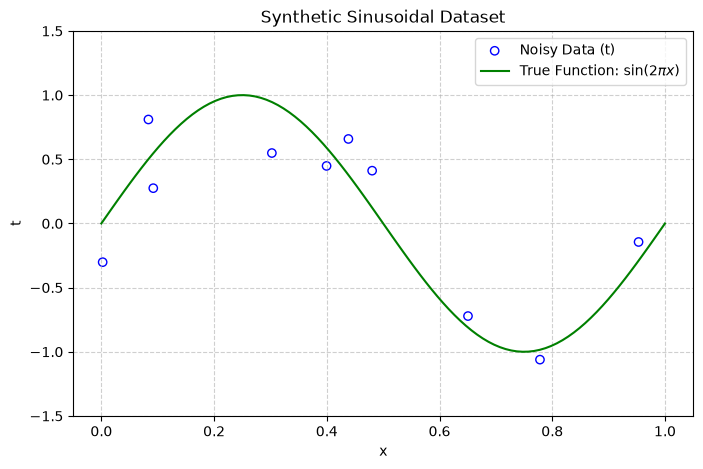

In [30]:
plt.figure(figsize=(8,5))
plt.scatter(x_data, t_data, facecolors='none', edgecolors='blue', label='Noisy Data (t)')

x_smooth = jnp.linspace(0, 1, 100)
true_y = jnp.sin(2*jnp.pi*x_smooth)
plt.plot(x_smooth, true_y, color='green', label='True Function: $\sin(2\pi x)$')

plt.title("Synthetic Sinusoidal Dataset")
plt.xlabel("x")
plt.ylabel("t")
plt.xlim(-0.05, 1.05)
plt.ylim(-1.5, 1.5)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

## Curve Fitting

In [31]:
def polynomial_features(x, M):
    """
    Transforms 1D input data into a polynomial design matrix.

    Args:
        x: 1D array of input features (shape: N,)
        M: The degree of the polynomial

    Returns:
        A 2D design matrix of shape (N, M+1) where columns are x^0, x^1, ..., x^M
    """
    return jnp.vander(x, N=M+1, increasing=True)

@jax.jit
def predict(w, phi):
    """
    Generates predictions using the weights and the design matrix.

    Args:
        w: Weight vector of shape (M+1,)
        phi: Design matrix of shape (N, M+1)
    
    Returns:
        1D array of predictions (shape: N,)
    """
    return jnp.dot(phi, w)

@jax.jit
def sum_of_squares_error(w, phi, t):
    """
    Computes the Sum of Squares Error.

    Args:
        w: Weight vector of shape (M+1,)
        phi: Design matrix of shape (N, M+1)
        t: Target values (shape: N,)

    Returns:
        A scalar representing the error.
    """
    predictions = predict(w, phi)
    return 0.5 * jnp.sum((predictions-t)**2)

@jax.jit
def update_weights(w, phi, t, learning_rate):
    """
    Computes the gradient and updates weights in one step.

    Args:
        w: Weight vector of shape (M+1,)
        phi: Design matrix of shape (N, M+1)
        t: Target values (shape: N,)
        learning_rate: learning rate

    Returns:
        A vector representing the updated weight of shape (M+1,)
    """
    gradient = jax.grad(sum_of_squares_error)(w, phi, t)
    return w-learning_rate*gradient

<>:23: SyntaxWarning: invalid escape sequence '\s'
<>:23: SyntaxWarning: invalid escape sequence '\s'
/var/folders/mr/gyhq4nd5159cfdvmmd1l_d440000gn/T/ipykernel_24818/862387990.py:23: SyntaxWarning: invalid escape sequence '\s'
  ax.plot(x_smooth, true_y, color='green', label='$\sin(2\pi x)$')


Optimized Weights for M=0: 
 [0.09222828]
Optimized Weights for M=1: 
 [ 0.5179014 -1.0181977]
Optimized Weights for M=3: 
 [ -0.08255636   8.022561   -22.656683    14.588348  ]
Optimized Weights for M=9: 
 [-0.04306814  5.1416426  -7.7811112  -2.6547093  -1.5533863   1.3596649
  1.9834994   0.7112688   1.8098984   2.0999527 ]


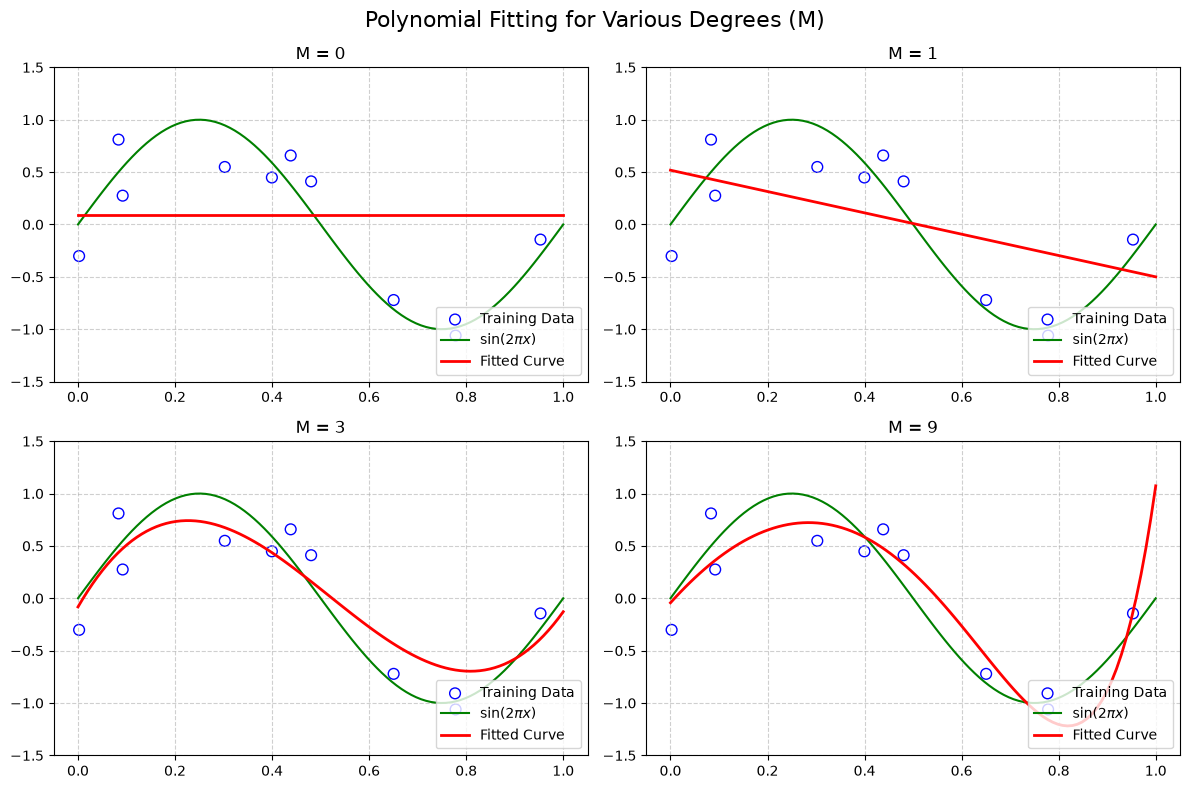

In [38]:
M_candidates = [0, 1, 3, 9]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Polynomial Fitting for Various Degrees (M)", fontsize=16)

for M, ax in zip(M_candidates, axes.flatten()):
    phi_x = polynomial_features(x_data, M)
    phi_smooth = polynomial_features(x_smooth, M)

    key_w = jax.random.PRNGKey(24)
    w = jax.random.normal(key_w, shape=(M+1,))

    epochs = 10000
    learning_rate = 0.1

    for _ in range(epochs):
        w = update_weights(w, phi_x, t_data, learning_rate)
    
    print(f"Optimized Weights for M={M}: \n {w}")

    y_pred_smooth = predict(w, phi_smooth)

    ax.scatter(x_data, t_data, facecolors='none', edgecolors='blue', s=60, label='Training Data')
    ax.plot(x_smooth, true_y, color='green', label='$\sin(2\pi x)$')
    ax.plot(x_smooth, y_pred_smooth, color='red', linewidth=2, label=f'Fitted Curve')

    ax.set_title(f"M = {M}")
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-1.5, 1.5)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

Higher polynomial degree(M) roughly correlates to better fit

## Overfitting Demonstration

In [39]:
@jax.jit
def rmse(predictions, targets):
    """Calculates the Root Mean Squared Error."""
    return jnp.sqrt(jnp.mean((predictions - targets)**2))

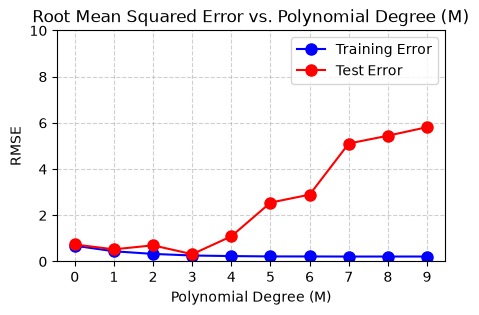

In [ ]:
train_key, test_key = jax.random.split(root_key)
x_train, t_train = generate_sinusoidal_data(train_key, num_points=10)
x_test, t_test = generate_sinusoidal_data(test_key, num_points=100)

M_candidates = range(10)
train_errors = []
test_errors = []

for M in M_candidates:
    phi_train = polynomial_features(x_train, M)
    phi_test = polynomial_features(x_test, M)

    w = jnp.linalg.pinv(phi_train) @ t_train # closed-form solution to the otherwise iterative gradient descent method
    pred_train = jnp.dot(phi_train, w)
    pred_test = jnp.dot(phi_test, w)

    train_errors.append(rmse(pred_train, t_train))
    test_errors.append(rmse(pred_test, t_test))

plt.figure(figsize=(5,3))
plt.plot(M_candidates, train_errors, marker='o', markersize=8, color='blue', label='Training Error')
plt.plot(M_candidates, test_errors, marker='o', markersize=8, color='red', label='Test Error')

plt.title("Root Mean Squared Error vs. Polynomial Degree (M)")
plt.xlabel("Polynomial Degree (M)")
plt.ylabel("RMSE")
plt.xticks(M_candidates)

plt.ylim(0, 10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()


Higher degree displays worse generalizability due to overfitting. Overfitting is signalled by the divergence of the continuously decreasing training error and increasing test error.

## Ways to mitigate overfitting

## Increase N

<>:36: SyntaxWarning: invalid escape sequence '\s'
<>:36: SyntaxWarning: invalid escape sequence '\s'
/var/folders/mr/gyhq4nd5159cfdvmmd1l_d440000gn/T/ipykernel_24818/3228055155.py:36: SyntaxWarning: invalid escape sequence '\s'
  ax.plot(x_smooth, true_y, color='green', label='$\sin(2\pi x)$')


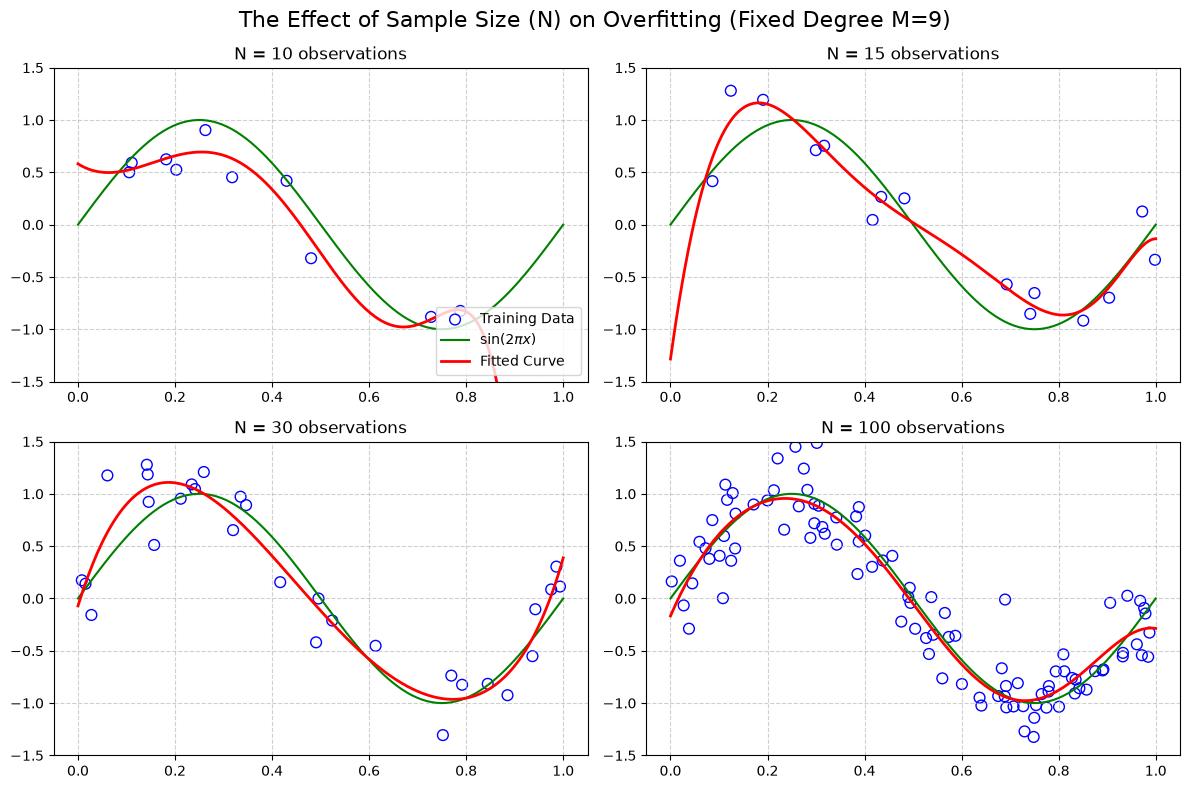

In [51]:
M = 9 
N_candidates = [10, 15, 30, 100] 

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle(f"The Effect of Sample Size (N) on Overfitting (Fixed Degree M={M})", fontsize=16)

# High resolution x for drawing smooth curves
x_smooth = jnp.linspace(0, 1, 200)
true_y = jnp.sin(2 * jnp.pi * x_smooth)
phi_smooth = polynomial_features(x_smooth, M)

key = jax.random.PRNGKey(42)

for N, ax in zip(N_candidates, axes.flatten()):
    # 1. GENERATE DATA DYNAMICALLY FOR EACH N
    key, subkey1, subkey2 = jax.random.split(key, 3)
    x_data = jax.random.uniform(subkey1, shape=(N,))
    
    # Add Gaussian noise
    noise = jax.random.normal(subkey2, shape=(N,)) * 0.25 
    t_data = jnp.sin(2 * jnp.pi * x_data) + noise
    
    phi_x = polynomial_features(x_data, M)

    # 2. FIT THE MODEL 
    # (Using the analytical MLE/OLS solver for M=9 stability. 
    # A tiny 1e-6 regularization is added just to prevent matrix singularity)
    A = phi_x.T @ phi_x + 1e-6 * jnp.eye(M + 1)
    b = phi_x.T @ t_data
    w = jax.scipy.linalg.solve(A, b)

    # 3. PREDICT & PLOT
    y_pred_smooth = jnp.dot(phi_smooth, w)

    ax.scatter(x_data, t_data, facecolors='none', edgecolors='blue', s=60, label='Training Data')
    ax.plot(x_smooth, true_y, color='green', label='$\sin(2\pi x)$')
    ax.plot(x_smooth, y_pred_smooth, color='red', linewidth=2, label='Fitted Curve')

    ax.set_title(f"N = {N} observations")
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-1.5, 1.5)
    ax.grid(True, linestyle='--', alpha=0.6)
    
    if N == N_candidates[0]: # Only put legend on the first plot to save space
        ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

From above, we can visually examine that the greater the number of samples, the less prone the fitted line is to overfitting.

## Add Regularization

In [56]:
@jax.jit
def regularized_error(w, phi, t, lam):
    """
    Computes the regularized Sum of Squares Error.

    Args:
        w: Weight vector of shape (M+1,)
        phi: Design matrix of shape (N, M+1)
        t: Target values (shape: N,)
        lam: Regularization coefficient (lambda)

    Returns:
        A scalar representing the regularized error.
    """
    predictions = predict(w, phi)
    sse = 0.5 * jnp.sum((predictions-t)**2)
    penalty = (lam / 2) * jnp.sum(w **2)

    return  sse + penalty

@jax.jit
def update_weights_regularized(w, phi, t, learning_rate, lam):
    """
    Computes the gradient and updates weights in one step.

    Args:
        w: Weight vector of shape (M+1,)
        phi: Design matrix of shape (N, M+1)
        t: Target values (shape: N,)
        learning_rate: learning rate

    Returns:
        A vector representing the updated weight of shape (M+1,)
    """
    gradient = jax.grad(regularized_error)(w, phi, t, lam)
    return w-learning_rate*gradient

In [58]:
root_key = jax.random.PRNGKey(24)

x_data, t_data = generate_sinusoidal_data(root_key, num_points=10)

<>:24: SyntaxWarning: invalid escape sequence '\s'
<>:24: SyntaxWarning: invalid escape sequence '\s'
/var/folders/mr/gyhq4nd5159cfdvmmd1l_d440000gn/T/ipykernel_24818/3934268063.py:24: SyntaxWarning: invalid escape sequence '\s'
  ax.plot(x_smooth, true_y, color='green', label='$\sin(2\pi x)$')


Optimized Weights for M=0: 
 [0.09131513]
Optimized Weights for M=1: 
 [ 0.46156552 -0.89448434]
Optimized Weights for M=3: 
 [ 0.37183005 -0.06290741 -0.7804084  -0.27375764]
Optimized Weights for M=9: 
 [ 0.3912492   0.19292016 -1.0537046  -0.978786   -0.57759714 -0.1550113
  0.19929941  0.4698921   0.66551125  0.80070084]


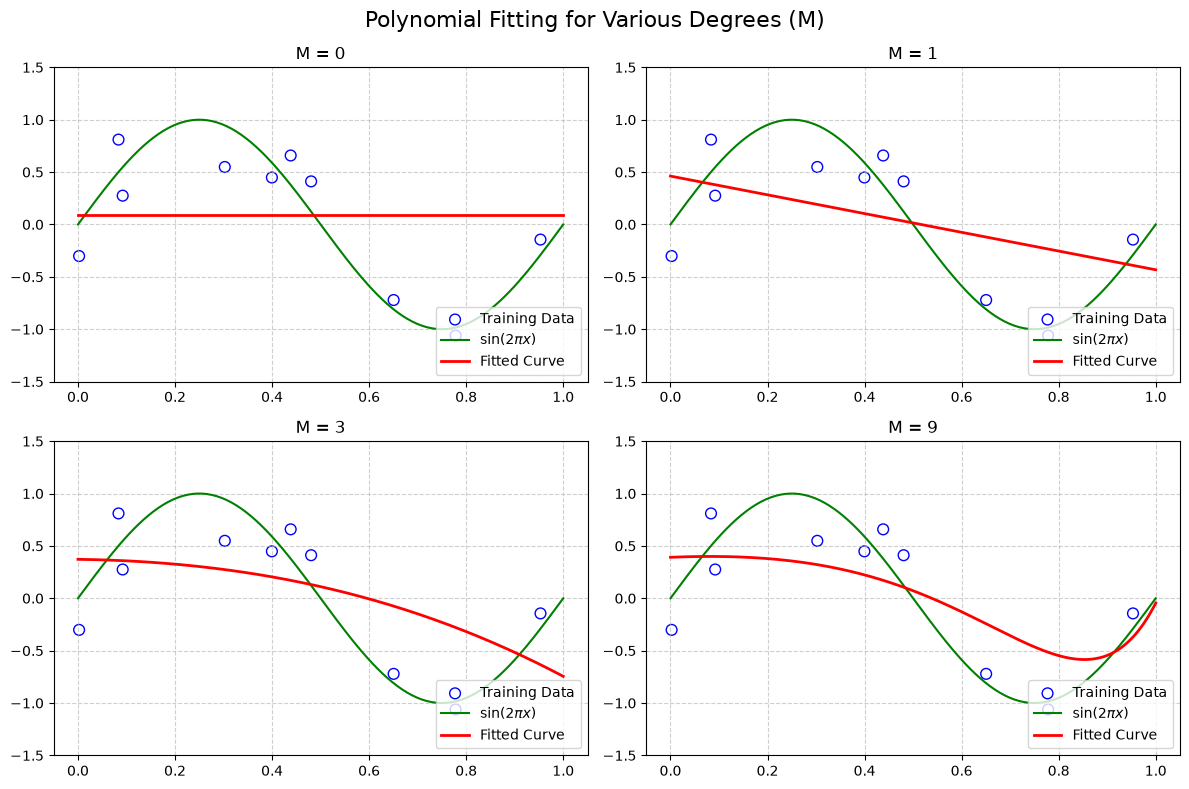

In [59]:
M_candidates = [0, 1, 3, 9]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Polynomial Fitting for Various Degrees (M)", fontsize=16)

for M, ax in zip(M_candidates, axes.flatten()):
    phi_x = polynomial_features(x_data, M)
    phi_smooth = polynomial_features(x_smooth, M)

    key_w = jax.random.PRNGKey(24)
    w = jax.random.normal(key_w, shape=(M+1,))

    epochs = 10000
    learning_rate = 0.1
    lam = 0.1

    for _ in range(epochs):
        w = update_weights_regularized(w, phi_x, t_data, learning_rate, lam)
    
    print(f"Optimized Weights for M={M}: \n {w}")

    y_pred_smooth = predict(w, phi_smooth)

    ax.scatter(x_data, t_data, facecolors='none', edgecolors='blue', s=60, label='Training Data')
    ax.plot(x_smooth, true_y, color='green', label='$\sin(2\pi x)$')
    ax.plot(x_smooth, y_pred_smooth, color='red', linewidth=2, label=f'Fitted Curve')

    ax.set_title(f"M = {M}")
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-1.5, 1.5)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

Adding a regularization also helps to mitigate the issue of overfitting

### Effect of lambda

<>:28: SyntaxWarning: invalid escape sequence '\s'
<>:32: SyntaxWarning: invalid escape sequence '\l'
<>:28: SyntaxWarning: invalid escape sequence '\s'
<>:32: SyntaxWarning: invalid escape sequence '\l'
/var/folders/mr/gyhq4nd5159cfdvmmd1l_d440000gn/T/ipykernel_24818/1275960973.py:28: SyntaxWarning: invalid escape sequence '\s'
  ax.plot(x_smooth, true_y, color='green', label='$\sin(2\pi x)$')
/var/folders/mr/gyhq4nd5159cfdvmmd1l_d440000gn/T/ipykernel_24818/1275960973.py:32: SyntaxWarning: invalid escape sequence '\l'
  ax.set_title(f"$\lambda$ = {lam}")


Optimized Weights for Lambda=0.0:
[ 0.04843649  3.5108166  -3.9430714  -2.8820362  -3.2702258  -0.3712494
  0.9099057   0.5852878   2.7139807   3.9940228 ]

Optimized Weights for Lambda=0.0001:
[ 0.05013788  3.4960074  -3.9287932  -2.8818338  -3.2512267  -0.3727456
  0.90562266  0.59503007  2.7044172   3.9733927 ]

Optimized Weights for Lambda=0.01:
[ 0.17757285  2.3720412  -2.8938565  -2.6317089  -2.035339   -0.417326
  0.61758876  1.0338341   2.0087132   2.6243362 ]

Optimized Weights for Lambda=1.0:
[ 0.27359498 -0.1672495  -0.2828376  -0.23236746 -0.15216482 -0.07792714
 -0.01823691  0.02682103  0.05956847  0.0826508 ]



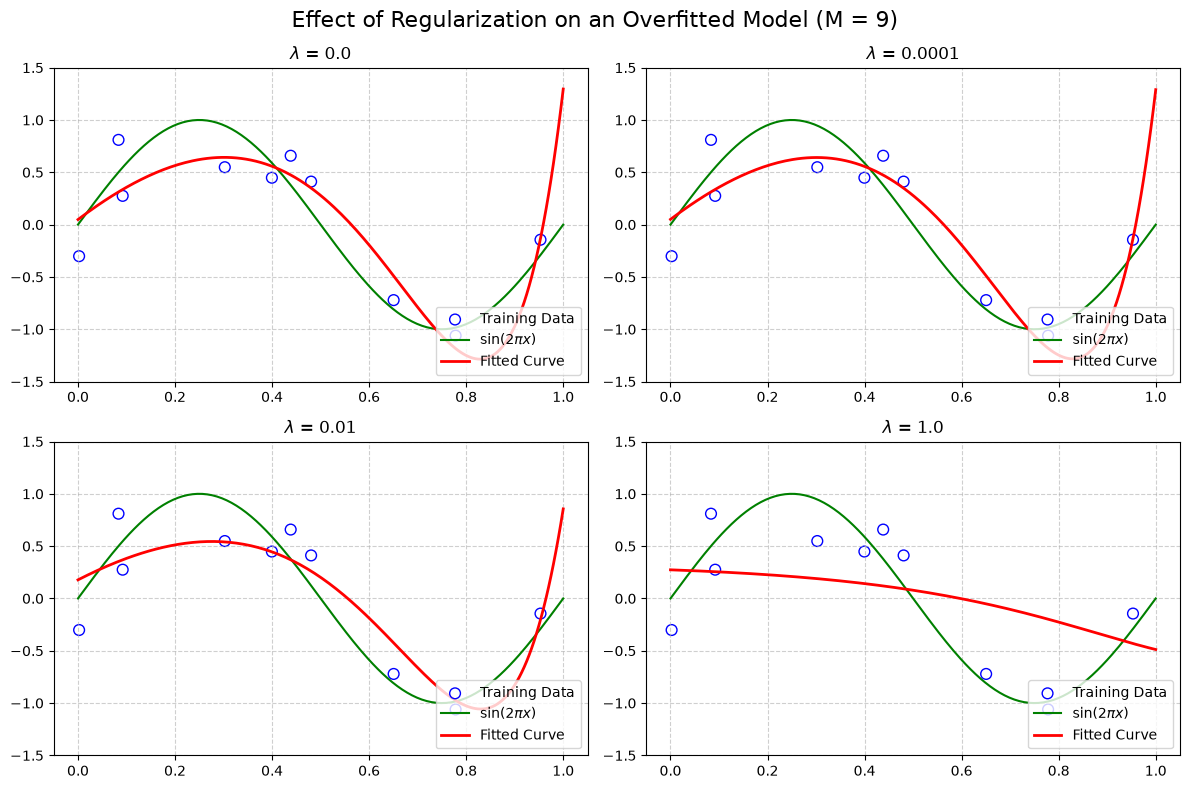

In [61]:
M = 9

phi_x = polynomial_features(x_data, M)
phi_smooth = polynomial_features(x_smooth, M)

lam_candidates = [0.0, 0.0001, 0.01, 1.0]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle(f"Effect of Regularization on an Overfitted Model (M = {M})", fontsize=16)

for lam, ax in zip(lam_candidates, axes.flatten()):
    
    key_w = jax.random.PRNGKey(24)
    w = jax.random.normal(key_w, shape=(M + 1,))

    epochs = 25000
    learning_rate = 0.005

    for _ in range(epochs):
        w = update_weights_regularized(w, phi_x, t_data, learning_rate, lam)
    
    print(f"Optimized Weights for Lambda={lam}:\n{w}\n")

    # Predict and Plot
    y_pred_smooth = predict(w, phi_smooth)

    ax.scatter(x_data, t_data, facecolors='none', edgecolors='blue', s=60, label='Training Data')
    ax.plot(x_smooth, true_y, color='green', label='$\sin(2\pi x)$')
    ax.plot(x_smooth, y_pred_smooth, color='red', linewidth=2, label='Fitted Curve')

    # Formatting
    ax.set_title(f"$\lambda$ = {lam}")
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-1.5, 1.5)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

<>:40: SyntaxWarning: invalid escape sequence '\l'
<>:41: SyntaxWarning: invalid escape sequence '\l'
<>:40: SyntaxWarning: invalid escape sequence '\l'
<>:41: SyntaxWarning: invalid escape sequence '\l'
/var/folders/mr/gyhq4nd5159cfdvmmd1l_d440000gn/T/ipykernel_24818/2365677151.py:40: SyntaxWarning: invalid escape sequence '\l'
  plt.title(f"RMSE vs. $\ln(\lambda)$ (Fixed Degree M={M})")
/var/folders/mr/gyhq4nd5159cfdvmmd1l_d440000gn/T/ipykernel_24818/2365677151.py:41: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel("$\ln(\lambda)$")


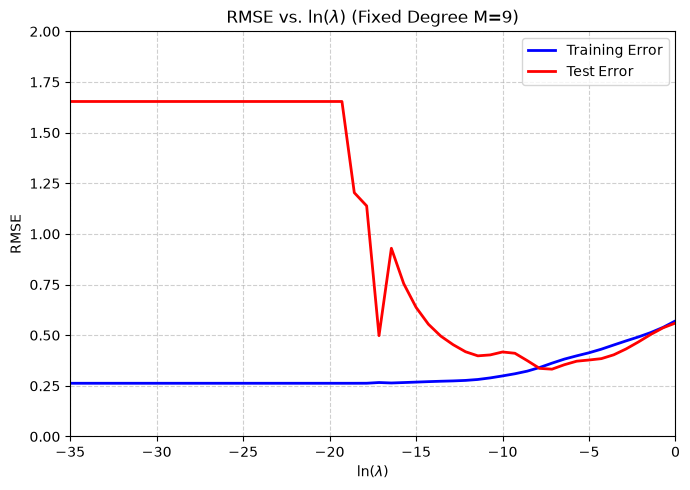

In [64]:
root_key = jax.random.PRNGKey(2026)
train_key, test_key = jax.random.split(root_key)

x_train, t_train = generate_sinusoidal_data(train_key, num_points=10)
x_test, t_test = generate_sinusoidal_data(test_key, num_points=100)

M = 9 # Fix M to 9 to start with an overfitted model
phi_train = polynomial_features(x_train, M)
phi_test = polynomial_features(x_test, M)

# Create an array of ln(lambda) values from -35 to 0 (very small to large penalty)
ln_lambdas = jnp.linspace(-35, 0, 50)
lambdas = jnp.exp(ln_lambdas) 

train_errors = []
test_errors = []

# Identity matrix for the regularization term (shape: M+1 x M+1)
I = jnp.eye(M + 1)

for lam in lambdas:
    A = jnp.dot(phi_train.T, phi_train) + lam * I
    b = jnp.dot(phi_train.T, t_train)
    
    w = jnp.linalg.solve(A, b)
    
    # Predictions
    pred_train = jnp.dot(phi_train, w)
    pred_test = jnp.dot(phi_test, w)

    # Calculate and store RMSE
    train_errors.append(rmse(pred_train, t_train))
    test_errors.append(rmse(pred_test, t_test))

plt.figure(figsize=(7, 5))

plt.plot(ln_lambdas, train_errors, color='blue', linewidth=2, label='Training Error')
plt.plot(ln_lambdas, test_errors, color='red', linewidth=2, label='Test Error')

plt.title(f"RMSE vs. $\ln(\lambda)$ (Fixed Degree M={M})")
plt.xlabel("$\ln(\lambda)$")
plt.ylabel("RMSE")

# Set the x-axis limits to match the range of ln(lambda)
plt.xlim(-35, 0)
plt.ylim(0, 2) 

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()